# 08 · PyTorch data loader for sequential recommendation (Part B)

### What this notebook does
Turns `sequences.parquet` into PyTorch batches for SASRec (Model 0) and every later model:

| Mode | Input (50 item IDs, left-padded with 0) | Target | Used for |
|---|---|---|---|
| `train` | training history without its last item | the same history shifted by one (next item at every position) | learning |
| `val` | last 50 training items | `val_item` | NDCG@10 after every epoch, early stopping |
| `test` | last 50 of training items + `val_item` | `test_item` | final reported score (once) |

**Example.** A user bought `[12, 45, 7, 88, 30]`, then `val_item = 51`, then `test_item = 9`:
- train: input `[0, …, 0, 12, 45, 7, 88]` → target `[0, …, 0, 45, 7, 88, 30]`
- val:   input `[0, …, 12, 45, 7, 88, 30]` → target `51`
- test:  input `[0, …, 45, 7, 88, 30, 51]` → target `9`

### Why left padding?
SASRec reads the sequence left to right with a causal mask and predicts from the **last position**. Putting padding
on the left keeps the most recent purchase in the same place (position 49) for every user.

### Contents
1. Load and inspect `sequences.parquet`
2. Sequence-building functions (plain NumPy, easy to check)
3. `SequenceDataset` class and `make_dataloaders()`
4. Fast GPU-friendly validation metrics for the training loop (`evaluate_loader`)
5. Tests: shapes, padding, shifting, leakage, agreement with `rec_eval.py`
6. Interface contract for the SASRec model (Part A)

To use the loader in the SASRec notebook, copy the cells in sections 2–4 into it (they have no other dependencies).

### Where files are read and written
Everything happens in **one folder**: `MyDrive/298A/04_Data/NewDataRunFiles/processed/`.
- **Reads:** `sequences.parquet` (required); `dataset_info.json` and `rec_eval.py` (optional, for test 5c)
- **Writes:** `08_history_length.png` and `dataloader_summary.json`. Nothing else is created anywhere.

If the folder moves, change `DATA_DIR` in the next cell.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)
sys.dont_write_bytecode = True          # importing rec_eval.py must not create a __pycache__ folder in DATA_DIR

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

# Input and output folder (the same folder). Change this line if the data moves.
DATA_DIR = Path(os.environ.get('RECSYS_DATA_DIR', '/content/drive/MyDrive/298A/04_Data/NewDataRunFiles/processed'))
OUT_DIR = DATA_DIR
assert (DATA_DIR / 'sequences.parquet').exists(), f'sequences.parquet not found in {DATA_DIR}'

PRIMARY, ACCENT, MUTED = '#2a78d6', '#eb6834', '#8a8984'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.edgecolor': '#b5b4ae',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
})

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str))

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

print('Data and output folder:', DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data and output folder: /content/drive/MyDrive/298A/04_Data/NewDataRunFiles/processed


## 1. Load `sequences.parquet`

In [2]:
import torch
from torch.utils.data import Dataset, DataLoader

SEQ_PATH = DATA_DIR / 'sequences.parquet'
sequences = pd.read_parquet(SEQ_PATH).sort_values('user_idx').reset_index(drop=True)

MAX_LEN = 50
SEED = 42
info_path = SEQ_PATH.parent / 'dataset_info.json'
if info_path.exists():
    info = json.loads(info_path.read_text())
    N_ITEMS, MAX_LEN = info['n_items'], info['max_seq_len']
else:
    N_ITEMS = int(max(sequences.train_items.apply(max).max(), sequences.val_item.max(), sequences.test_item.max()))

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'File: {SEQ_PATH}')
print(f'Users: {len(sequences):,} | items: {N_ITEMS:,} (IDs 1..{N_ITEMS}, 0 = padding) | MAX_LEN = {MAX_LEN} | device: {DEVICE}')
sequences.head(3)

File: /content/drive/MyDrive/298A/04_Data/NewDataRunFiles/processed/sequences.parquet
Users: 56,017 | items: 25,903 (IDs 1..25903, 0 = padding) | MAX_LEN = 50 | device: cuda


,user_idx,train_items,train_ts,val_item,val_ts,test_item,test_ts,n_train
0,0,"[10493, 8934, 6553, 10027, 16519, 22575]","[1570900999309, 1571890093750, 1571890171813, ...",18232,1641668829909,25472,1643176260453,6
1,1,"[16500, 3713, 4538]","[1394018735000, 1394018985000, 1403087218000]",3648,1454116522000,15589,1626617177996,3
2,2,"[22576, 2206, 25337, 2432, 557, 23647, 2529, 2...","[1361088575000, 1361089628000, 1361090258000, ...",16820,1540838469940,13337,1563843271128,13


### What the sequences look like
Most Amazon users have short histories, so most rows will be mostly padding. Histories longer than 50 are cut to
the most recent 50 (the long tail is shown below).

count    56017.0
mean         7.0
std         15.8
min          3.0
25%          3.0
50%          4.0
75%          6.0
90%         10.0
99%         56.0
max        909.0
Name: train_items, dtype: float64
Users with more than 50 training items (older items are cut): 1.17%
Average share of padding in a training row: 89.5%


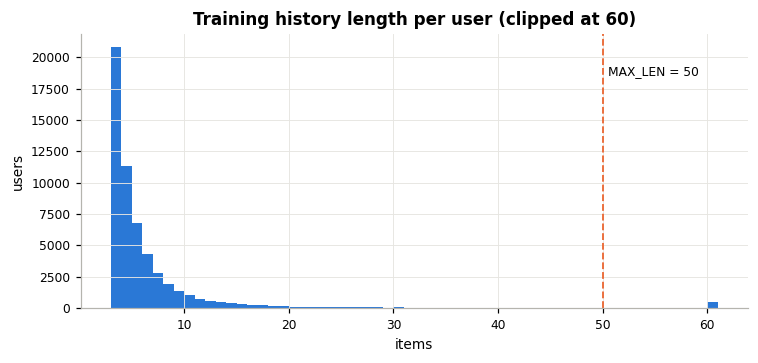

In [3]:
n_train = sequences.train_items.apply(len)
print(n_train.describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
print(f'Users with more than {MAX_LEN} training items (older items are cut): {(n_train > MAX_LEN).mean():.2%}')
print(f'Average share of padding in a training row: {1 - (n_train.clip(upper=MAX_LEN + 1) - 1).mean() / MAX_LEN:.1%}')

plt.figure(figsize=(7, 3.4))
plt.hist(n_train.clip(upper=60), bins=range(3, 62), color=PRIMARY)
plt.axvline(MAX_LEN, color=ACCENT, linewidth=1.2, linestyle='--')
plt.annotate(f'MAX_LEN = {MAX_LEN}', (MAX_LEN + 0.5, plt.ylim()[1] * 0.85), fontsize=8)
plt.title('Training history length per user (clipped at 60)'); plt.xlabel('items'); plt.ylabel('users')
savefig('08_history_length')

## 2. Sequence-building functions
These are plain NumPy so they are easy to read and test. They follow exactly the same rules as `rec_eval.py`
(notebook 07), which is checked in section 5.

**Long histories (`sliding_window`).** By default each user gives one training row: their most recent 51 items.
For the 1–2% of users with longer histories this ignores older purchases. With `sliding_window=True`, older history
is cut into extra rows of 51 items (each new row ends where the previous one starts). This uses all the training
data at the cost of more rows. Keep the default for the baseline and treat it as a hyperparameter to try.

In [4]:
def left_pad(seq, max_len):
    """Keep the last max_len items; pad with 0 on the left. Returns int64 array of length max_len."""
    seq = np.asarray(seq, dtype=np.int64)[-max_len:]
    out = np.zeros(max_len, dtype=np.int64)
    if len(seq):
        out[max_len - len(seq):] = seq
    return out


def training_windows(items, max_len, sliding_window=False):
    """Windows of up to max_len + 1 items from one user's training history, most recent first."""
    items = list(items)
    if not sliding_window:
        return [items[-(max_len + 1):]]
    windows, end = [], len(items)
    while end >= 2:
        windows.append(items[max(0, end - max_len - 1):end])
        end -= max_len          # the next window ends at the first item of this one
    return windows


def build_train_arrays(sequences, max_len, sliding_window=False):
    """input[t] = item at t, target[t] = item at t + 1. Both left-padded to max_len."""
    users, inputs, targets = [], [], []
    for u, items in zip(sequences.user_idx.to_numpy(), sequences.train_items):
        for w in training_windows(items, max_len, sliding_window):
            users.append(u)
            inputs.append(left_pad(w[:-1], max_len))
            targets.append(left_pad(w[1:], max_len))
    return np.asarray(users, dtype=np.int64), np.stack(inputs), np.stack(targets)


def build_eval_arrays(sequences, split, max_len):
    """Inputs, targets and full histories (items to hide when ranking) for 'val' or 'test'."""
    if split == 'val':
        histories = [np.asarray(t, dtype=np.int64) for t in sequences.train_items]
        targets = sequences.val_item.to_numpy(dtype=np.int64)
    elif split == 'test':
        histories = [np.append(np.asarray(t, dtype=np.int64), v) for t, v in zip(sequences.train_items, sequences.val_item)]
        targets = sequences.test_item.to_numpy(dtype=np.int64)
    else:
        raise ValueError("split must be 'val' or 'test'")
    inputs = np.stack([left_pad(h, max_len) for h in histories])
    return sequences.user_idx.to_numpy(dtype=np.int64), inputs, targets, histories

## 3. `SequenceDataset` and `make_dataloaders()`
All rows are built once when the dataset is created and stored as tensors, so loading a batch is just indexing
(fast, even with `num_workers=0`).

**What one item looks like**
- `train`: `{'user_idx': (), 'input_seq': (50,), 'target_seq': (50,)}`
- `val` / `test`: `{'user_idx': (), 'input_seq': (50,), 'target': (), 'history': (variable,)}`

The `history` tensor lists the items the user already has; the evaluation code hides them from the ranking.
Because histories have different lengths, `eval_collate` pads them with 0 into one `(batch, longest)` tensor.
Index 0 is the padding column and is never a real item, so hiding it is harmless.

In [5]:
class SequenceDataset(Dataset):
    """Next-item prediction data from sequences.parquet.

    mode='train' -> input_seq, target_seq (both length max_len, left-padded with 0)
    mode='val'   -> input_seq = last max_len training items, target = val_item
    mode='test'  -> input_seq = last max_len of training items + val_item, target = test_item
    """

    def __init__(self, sequences, mode='train', max_len=50, sliding_window=False):
        if mode not in ('train', 'val', 'test'):
            raise ValueError("mode must be 'train', 'val' or 'test'")
        self.mode, self.max_len = mode, max_len
        if mode == 'train':
            users, inputs, targets = build_train_arrays(sequences, max_len, sliding_window)
            self.histories = None
        else:
            users, inputs, targets, histories = build_eval_arrays(sequences, mode, max_len)
            self.histories = [torch.from_numpy(h) for h in histories]
        self.user_idx = torch.from_numpy(users)
        self.inputs = torch.from_numpy(inputs)
        self.targets = torch.from_numpy(targets)

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, i):
        if self.mode == 'train':
            return {'user_idx': self.user_idx[i], 'input_seq': self.inputs[i], 'target_seq': self.targets[i]}
        return {'user_idx': self.user_idx[i], 'input_seq': self.inputs[i], 'target': self.targets[i],
                'history': self.histories[i]}


def eval_collate(batch):
    """Stack fixed-size fields; pad the variable-length histories with 0."""
    return {
        'user_idx': torch.stack([b['user_idx'] for b in batch]),
        'input_seq': torch.stack([b['input_seq'] for b in batch]),
        'target': torch.stack([b['target'] for b in batch]),
        'history': torch.nn.utils.rnn.pad_sequence([b['history'] for b in batch], batch_first=True, padding_value=0),
    }


def make_dataloaders(sequences, max_len=50, batch_size=256, eval_batch_size=512, num_workers=0, seed=42,
                     sliding_window=False, pin_memory=None):
    """Returns {'train': ..., 'val': ..., 'test': ...} DataLoaders. Training order is shuffled with a fixed seed."""
    pin_memory = torch.cuda.is_available() if pin_memory is None else pin_memory
    g = torch.Generator().manual_seed(seed)
    train_ds = SequenceDataset(sequences, 'train', max_len, sliding_window)
    val_ds = SequenceDataset(sequences, 'val', max_len)
    test_ds = SequenceDataset(sequences, 'test', max_len)
    return {
        'train': DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g, drop_last=False,
                            num_workers=num_workers, pin_memory=pin_memory),
        'val': DataLoader(val_ds, batch_size=eval_batch_size, shuffle=False, collate_fn=eval_collate,
                          num_workers=num_workers, pin_memory=pin_memory),
        'test': DataLoader(test_ds, batch_size=eval_batch_size, shuffle=False, collate_fn=eval_collate,
                           num_workers=num_workers, pin_memory=pin_memory),
    }

In [6]:
t0 = time.time()
loaders = make_dataloaders(sequences, max_len=MAX_LEN, seed=SEED)
print(f'Built in {time.time() - t0:.1f}s')
for name, dl in loaders.items():
    print(f'{name:5s}: {len(dl.dataset):>7,} rows, {len(dl):>5,} batches')

/tmp/ipykernel_6819/1266471004.py:18: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.histories = [torch.from_numpy(h) for h in histories]


Built in 1.3s
train:  56,017 rows,   219 batches
val  :  56,017 rows,   110 batches
test :  56,017 rows,   110 batches


### One batch of each kind

In [7]:
tb = next(iter(loaders['train']))
vb = next(iter(loaders['val']))
print({k: (tuple(v.shape), v.dtype) for k, v in tb.items()})
print({k: (tuple(v.shape), v.dtype) for k, v in vb.items()})

u0 = sequences.iloc[0]
ds_tr, ds_va, ds_te = loaders['train'].dataset, loaders['val'].dataset, loaders['test'].dataset
print(f'\nUser {u0.user_idx}: training history {list(u0.train_items)}, val_item {u0.val_item}, test_item {u0.test_item}')
print('train input  (last 8):', ds_tr.inputs[0, -8:].tolist())
print('train target (last 8):', ds_tr.targets[0, -8:].tolist())
print('val input    (last 8):', ds_va.inputs[0, -8:].tolist(), '-> target', int(ds_va.targets[0]))
print('test input   (last 8):', ds_te.inputs[0, -8:].tolist(), '-> target', int(ds_te.targets[0]))

{'user_idx': ((256,), torch.int64), 'input_seq': ((256, 50), torch.int64), 'target_seq': ((256, 50), torch.int64)}
{'user_idx': ((512,), torch.int64), 'input_seq': ((512, 50), torch.int64), 'target': ((512,), torch.int64), 'history': ((512, 134), torch.int64)}

User 0: training history [np.int64(10493), np.int64(8934), np.int64(6553), np.int64(10027), np.int64(16519), np.int64(22575)], val_item 18232, test_item 25472
train input  (last 8): [0, 0, 0, 10493, 8934, 6553, 10027, 16519]
train target (last 8): [0, 0, 0, 8934, 6553, 10027, 16519, 22575]
val input    (last 8): [0, 0, 10493, 8934, 6553, 10027, 16519, 22575] -> target 18232
test input   (last 8): [0, 10493, 8934, 6553, 10027, 16519, 22575, 18232] -> target 25472


## 4. Validation metrics for the training loop
During training, NDCG@10 is computed after every epoch for early stopping. `evaluate_loader` does this on the GPU
with the same rules as `rec_eval.py`: rank against the **full catalog**, **hide items the user already has**, and
break score ties fairly (expected rank under random tie-breaking).

`score_fn(input_seq, user_idx)` must return scores of shape `(batch, N_ITEMS + 1)`; column 0 (padding) is ignored.
For SASRec this is usually the dot product of the last position's output with the item embedding table.

Use this for per-epoch validation and the training-curve diagnostics. Report final test numbers with
`rec_eval.evaluate` (section 5c shows both give the same result).

In [8]:
@torch.no_grad()
def evaluate_loader(score_fn, loader, ks=(5, 10, 20), device=DEVICE):
    ranks = []
    for batch in loader:
        x = batch['input_seq'].to(device, non_blocking=True)
        u = batch['user_idx'].to(device, non_blocking=True)
        tgt = batch['target'].to(device, non_blocking=True)
        hist = batch['history'].to(device, non_blocking=True)
        scores = score_fn(x, u).float().clone()
        scores[:, 0] = -float('inf')                               # padding column
        target_score = scores.gather(1, tgt[:, None])              # read before masking (target is never in history)
        scores.scatter_(1, hist, -float('inf'))                    # hide items already in the history
        greater = (scores > target_score).sum(1)
        equal = (scores == target_score).sum(1) - 1
        ranks.append((1 + greater + equal / 2.0).double().cpu())
    ranks = torch.cat(ranks)
    out = {}
    for k in ks:
        hit = ranks <= k
        out[f'Recall@{k}'] = hit.double().mean().item()
        out[f'NDCG@{k}'] = torch.where(hit, 1.0 / torch.log2(ranks + 1.0), torch.zeros_like(ranks)).mean().item()
    out['MRR'] = (1.0 / ranks).mean().item()
    return out

## 5. Tests
Every check below must print PASS. They run on the full dataset, not a sample.

### 5a. Shapes, types, padding and shifting

In [9]:
def check(name, cond):
    print(('PASS ' if cond else 'FAIL ') + name)
    assert cond, name

L = MAX_LEN
X, Y = ds_tr.inputs.numpy(), ds_tr.targets.numpy()
check('train tensors are int64 with shape (rows, MAX_LEN)',
      ds_tr.inputs.dtype == torch.int64 and X.shape == Y.shape == (len(sequences), L))
check('all IDs in 0..N_ITEMS', X.min() >= 0 and X.max() <= N_ITEMS and Y.max() <= N_ITEMS)

def left_padded(A):
    nz = A > 0
    first = np.where(nz.any(1), nz.argmax(1), A.shape[1])
    return bool((nz == (np.arange(A.shape[1])[None, :] >= first[:, None])).all())

check('train inputs are left-padded (no zeros after the first item)', left_padded(X))
check('train targets are left-padded', left_padded(Y))
check('input and target padding positions line up', ((X == 0) == (Y == 0)).all())
both = (X[:, :-1] > 0) & (X[:, 1:] > 0)
check('target at position t equals input at position t+1', (Y[:, :-1][both] == X[:, 1:][both]).all())
check('last train target is the last training item of each user',
      (Y[:, -1] == np.array([t[-1] for t in sequences.train_items])).all())
check('train rows use the most recent items (cut at MAX_LEN)',
      all((X[i][X[i] > 0] == np.asarray(t)[-(L + 1):-1]).all() for i, t in enumerate(sequences.train_items)))

PASS train tensors are int64 with shape (rows, MAX_LEN)
PASS all IDs in 0..N_ITEMS
PASS train inputs are left-padded (no zeros after the first item)
PASS train targets are left-padded
PASS input and target padding positions line up
PASS target at position t equals input at position t+1
PASS last train target is the last training item of each user
PASS train rows use the most recent items (cut at MAX_LEN)


### 5b. Validation and test inputs, and leakage

In [10]:
Xv, yv = ds_va.inputs.numpy(), ds_va.targets.numpy()
Xt, yt = ds_te.inputs.numpy(), ds_te.targets.numpy()
check('val/test inputs are left-padded', left_padded(Xv) and left_padded(Xt))
check('val input = last MAX_LEN training items',
      all((Xv[i][Xv[i] > 0] == np.asarray(t)[-L:]).all() for i, t in enumerate(sequences.train_items)))
check('val target = val_item', (yv == sequences.val_item.values).all())
check('test input ends with val_item', (Xt[:, -1] == sequences.val_item.values).all())
check('test input = last MAX_LEN of training items + val_item',
      all((Xt[i][Xt[i] > 0] == np.append(t, v)[-L:]).all()
          for i, (t, v) in enumerate(zip(sequences.train_items, sequences.val_item))))
check('test target = test_item', (yt == sequences.test_item.values).all())
check('val target never appears in its own input or history',
      not any(int(yv[i]) in set(h.tolist()) for i, h in enumerate(ds_va.histories)))
check('test target never appears in its own input or history',
      not any(int(yt[i]) in set(h.tolist()) for i, h in enumerate(ds_te.histories)))
check('last input position never equals last target (no copy-through)', not (X[:, -1] == Y[:, -1]).any())

PASS val/test inputs are left-padded
PASS val input = last MAX_LEN training items
PASS val target = val_item
PASS test input ends with val_item
PASS test input = last MAX_LEN of training items + val_item
PASS test target = test_item
PASS val target never appears in its own input or history
PASS test target never appears in its own input or history
PASS last input position never equals last target (no copy-through)


In [11]:
sw = SequenceDataset(sequences, 'train', MAX_LEN, sliding_window=True)
long_users = int((n_train > L + 1).sum())
rows_per_user = np.bincount(sw.user_idx.numpy(), minlength=len(sequences))
long_mask = (n_train > L + 1).to_numpy()
check('sliding_window: every user keeps at least one row', (rows_per_user >= 1).all())
check('sliding_window: extra rows only for users with more than MAX_LEN + 1 training items',
      (rows_per_user[~long_mask] == 1).all() and (rows_per_user[long_mask] > 1).all())
check('sliding_window rows still satisfy the shift rule',
      (sw.targets.numpy()[:, :-1][(sw.inputs.numpy()[:, :-1] > 0) & (sw.inputs.numpy()[:, 1:] > 0)] ==
       sw.inputs.numpy()[:, 1:][(sw.inputs.numpy()[:, :-1] > 0) & (sw.inputs.numpy()[:, 1:] > 0)]).all())
print(f'sliding_window=True: {len(sw):,} training rows vs {len(ds_tr):,} by default ({long_users:,} long users)')
del sw

PASS sliding_window: every user keeps at least one row
PASS sliding_window: extra rows only for users with more than MAX_LEN + 1 training items
PASS sliding_window rows still satisfy the shift rule
sliding_window=True: 57,163 training rows vs 56,017 by default (631 long users)


### 5c. Agreement with `rec_eval.py` (notebook 07)
The loader must give the model exactly the same arrays that the shared evaluation module uses, and per-epoch
validation must give the same numbers as the official evaluation. Skipped (with a message) if `rec_eval.py` and the
notebook-05/07 outputs are not in the same `processed/` folder.

In [12]:
needed = ['rec_eval.py', 'dataset_info.json', 'eval/eval_protocol.json', 'eval/neg_val.npy', 'eval/neg_test.npy',
          'eval/eval_cases.parquet', 'groups/item_groups.parquet', 'groups/user_groups.parquet']
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if not missing:
    sys.path.insert(0, str(SEQ_PATH.parent))
    import importlib, rec_eval as R
    importlib.reload(R)
    Xr, Yr = R.train_arrays(sequences, L)
    check('train arrays identical to rec_eval.train_arrays', np.array_equal(Xr, X) and np.array_equal(Yr, Y))
    for split, ds in [('val', ds_va), ('test', ds_te)]:
        Xe, ye, _ = R.eval_arrays(sequences, split, L)
        check(f'{split} arrays identical to rec_eval.eval_arrays',
              np.array_equal(Xe, ds.inputs.numpy()) and np.array_equal(ye, ds.targets.numpy()))

    # Same metrics from both evaluators, using a simple popularity scorer.
    pop = torch.bincount(ds_tr.targets.flatten(), minlength=N_ITEMS + 1).float()
    pop[0] = 0
    pop_dev = pop.to(DEVICE)
    torch_scores = lambda x, u: pop_dev.expand(len(u), -1)
    m_torch = evaluate_loader(torch_scores, loaders['val'])
    data = R.load_dataset(SEQ_PATH.parent)
    m_ref = R.evaluate(lambda x, u: np.broadcast_to(pop.numpy(), (len(u), N_ITEMS + 1)), data, split='val',
                       return_topk=False)['metrics']
    check('evaluate_loader matches rec_eval.evaluate (NDCG@10, Recall@10, MRR)',
          all(abs(m_torch[k] - m_ref[k]) < 1e-6 for k in ['NDCG@10', 'Recall@10', 'MRR']))
    print('popularity on validation:', {k: round(v, 4) for k, v in m_torch.items()})
else:
    print(f'Agreement test skipped: these files are not in {DATA_DIR}: {missing}')

PASS train arrays identical to rec_eval.train_arrays
PASS val arrays identical to rec_eval.eval_arrays
PASS test arrays identical to rec_eval.eval_arrays
PASS evaluate_loader matches rec_eval.evaluate (NDCG@10, Recall@10, MRR)
popularity on validation: {'Recall@5': 0.0169, 'NDCG@5': 0.0109, 'Recall@10': 0.0273, 'NDCG@10': 0.0142, 'Recall@20': 0.0417, 'NDCG@20': 0.0179, 'MRR': 0.014}


### 5d. Interface test with a tiny stand-in model
A two-layer stand-in (not SASRec) checks that the batches plug into a model, a loss and the evaluator the way
Part A's SASRec will use them: embedding with `padding_idx=0`, logits over `N_ITEMS + 1` items, loss only on real
(non-padded) positions, and scores from the last position. The full-loss comparison runs on GPU only, to save memory.

In [13]:
class TinyStandIn(torch.nn.Module):
    def __init__(self, n_items, d=32):
        super().__init__()
        self.item_emb = torch.nn.Embedding(n_items + 1, d, padding_idx=0)
        self.proj = torch.nn.Linear(d, d)

    def forward(self, x):                        # (B, L) -> (B, L, d)
        return torch.tanh(self.proj(self.item_emb(x)))

    def logits(self, h):                         # (..., d) -> (..., n_items + 1), tied to item embeddings
        return h @ self.item_emb.weight.T

torch.manual_seed(SEED)
model = TinyStandIn(N_ITEMS).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = torch.nn.CrossEntropyLoss(ignore_index=0)

model.train()
losses = []
for step, batch in enumerate(loaders['train']):
    x, y = batch['input_seq'].to(DEVICE), batch['target_seq'].to(DEVICE)
    h = model(x)                                                 # (B, L, d)
    # Memory tip: ~89% of positions are padding. Computing logits only where target > 0 cuts the
    # (B x L x N_ITEMS) logit tensor (~1.3 GB per batch of 256 here) by about 10x and gives the same loss.
    mask = y > 0
    logits = model.logits(h[mask])                               # (n_real_positions, N_ITEMS + 1)
    loss = loss_fn(logits, y[mask])
    if step == 0 and DEVICE.type == 'cuda':
        with torch.no_grad():
            full = loss_fn(model.logits(h).reshape(-1, N_ITEMS + 1), y.reshape(-1))
        check('masked loss equals the full ignore_index=0 loss', torch.allclose(loss.detach(), full, atol=1e-4))
        del full
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
    if step == 30:
        break
check('logits cover every real (non-padded) position', logits.shape == (int(mask.sum()), N_ITEMS + 1))
check('loss is finite', bool(np.isfinite(losses).all()))
print(f'loss: first step {losses[0]:.3f} -> step {len(losses) - 1} {losses[-1]:.3f} (ln(N_ITEMS) = {np.log(N_ITEMS):.3f})')

model.eval()
score_fn = lambda x, u: model.logits(model(x)[:, -1, :])         # last position -> (B, N_ITEMS + 1)
m = evaluate_loader(score_fn, loaders['val'])
check('evaluate_loader runs end to end and returns metrics in [0, 1]', all(0 <= v <= 1 for v in m.values()))
print('stand-in model after 30 steps (not meaningful, just a smoke test):', {k: round(v, 4) for k, v in m.items()})

PASS masked loss equals the full ignore_index=0 loss
PASS logits cover every real (non-padded) position
PASS loss is finite
loss: first step 13.570 -> step 30 12.506 (ln(N_ITEMS) = 10.162)
PASS evaluate_loader runs end to end and returns metrics in [0, 1]
stand-in model after 30 steps (not meaningful, just a smoke test): {'Recall@5': 0.0002, 'NDCG@5': 0.0001, 'Recall@10': 0.0003, 'NDCG@10': 0.0002, 'Recall@20': 0.0008, 'NDCG@20': 0.0003, 'MRR': 0.0004}


### 5e. Speed: one full pass over the training loader

In [14]:
t0 = time.time()
n_rows = 0
for batch in loaders['train']:
    n_rows += len(batch['input_seq'])
check('one pass covers every training row exactly once', n_rows == len(ds_tr))
print(f'One epoch of batches (data only, no model): {time.time() - t0:.2f}s for {n_rows:,} rows')

PASS one pass covers every training row exactly once
One epoch of batches (data only, no model): 0.41s for 56,017 rows


## 6. Interface contract for the SASRec model (Part A)

| Item | Data loader gives | SASRec must |
|---|---|---|
| Input | `input_seq`: `(batch, 50)`, `torch.int64` | have a positional embedding for 50 positions |
| Padding | `0`, on the **left**; most recent item at position 49 | use `nn.Embedding(N_ITEMS + 1, d, padding_idx=0)` and ignore padded positions in attention |
| Item IDs | `1 … N_ITEMS` | size the item table and output layer at `N_ITEMS + 1` |
| Training target | `target_seq`: `(batch, 50)`, next item at each position, `0` where padded | use cross-entropy over the full catalog, ignoring padded positions (`ignore_index=0`, or better, compute logits only where `target_seq > 0`: ~89% of positions are padding) |
| Order | oldest → newest, left to right | use a causal mask (position t sees only positions ≤ t) |
| Val / test | `input_seq` `(batch, 50)`, `target` `(batch,)`, `history` `(batch, *)` | return scores `(batch, N_ITEMS + 1)` from the last position, for `evaluate_loader` / `rec_eval.evaluate` |

**Training loop pattern**
```python
loaders = make_dataloaders(sequences, max_len=50, batch_size=256, seed=SEED)
for epoch in range(max_epochs):
    model.train()
    for batch in loaders['train']:
        x, y = batch['input_seq'].to(DEVICE), batch['target_seq'].to(DEVICE)
        h = model(x)                                   # (B, 50, d) hidden states
        mask = y > 0                                   # real positions only (saves ~10x memory)
        loss = loss_fn(h[mask] @ model.item_emb.weight.T, y[mask])
        ...
    model.eval()
    val = evaluate_loader(lambda x, u: model(x)[:, -1, :] @ model.item_emb.weight.T, loaders['val'])
    log.append({'epoch': epoch, 'train_loss': ..., **val})                # needed for the training diagnostics
    # early stopping on val['NDCG@10'], save the best checkpoint
```

In [15]:
summary = {
    'file': str(SEQ_PATH), 'n_users': int(len(sequences)), 'n_items': int(N_ITEMS), 'max_len': int(MAX_LEN),
    'train_rows_default': int(len(ds_tr)), 'val_rows': int(len(ds_va)), 'test_rows': int(len(ds_te)),
    'users_longer_than_max_len_pct': round(100 * float((n_train > MAX_LEN).mean()), 2),
    'all_tests_passed': True,
}
save_json(summary, OUT_DIR / 'dataloader_summary.json')
print('Saved', OUT_DIR / 'dataloader_summary.json', 'and', OUT_DIR / '08_history_length.png')
summary

Saved /content/drive/MyDrive/298A/04_Data/NewDataRunFiles/processed/dataloader_summary.json and /content/drive/MyDrive/298A/04_Data/NewDataRunFiles/processed/08_history_length.png


{'file': '/content/drive/MyDrive/298A/04_Data/NewDataRunFiles/processed/sequences.parquet',
 'n_users': 56017,
 'n_items': 25903,
 'max_len': 50,
 'train_rows_default': 56017,
 'val_rows': 56017,
 'test_rows': 56017,
 'users_longer_than_max_len_pct': 1.17,
 'all_tests_passed': True}